# 11 — 2026-10-25: the full run (as 06) with Qwen2.5-VL-7B-Instruct

Settings in `configs/2026-10-25_qwen25vl_full.toml`, results in `outputs/2026-10-25_qwen25vl_full/`; `prob_*` and `answer` use the original option letters, `option_order` and `answer_shown` what the model saw.

In [1]:
N_QUESTIONS = None  # None = all 598 questions
CONDITIONS = None  # None = all conditions in the config

In [2]:
import sys, json, random, time, tomllib
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import qwen_vl as mdl

CFG_PATH = ROOT / "configs/2026-10-25_qwen25vl_full.toml"
CFG = tomllib.loads(CFG_PATH.read_text())
CONDITIONS = CONDITIONS or CFG["conditions"]
assert set(CONDITIONS) <= set(CFG["conditions"]), CONDITIONS
EXP_DIR = ROOT / "outputs" / CFG["experiment"]
EXP_DIR.mkdir(parents=True, exist_ok=True)
OUT = EXP_DIR / "results.jsonl"

all_questions = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet")
questions = all_questions.head(N_QUESTIONS)
print(f"{len(questions)} questions, conditions {CONDITIONS} -> {OUT.relative_to(ROOT)}")

598 questions, conditions ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis'] -> outputs/2026-10-25_qwen25vl_full/results.jsonl


## Mismatched clips

Each question gets the clip of an Emotions question from a different film with the closest clip length.

In [3]:
mismatch = {}
for q in all_questions.itertuples():
    other = all_questions[all_questions.movie_title != q.movie_title]
    gap = (other.focused_duration_s - q.focused_duration_s).abs()
    mismatch[q.question_id] = other.loc[gap.idxmin()]

pairs = pd.DataFrame({"question_id": list(mismatch),
                      "clip_s": all_questions.focused_duration_s.values,
                      "mis_question_id": [m.question_id for m in mismatch.values()],
                      "mis_movie_title": [m.movie_title for m in mismatch.values()],
                      "mis_clip_s": [m.focused_duration_s for m in mismatch.values()]})
pairs.to_csv(EXP_DIR / "mismatch_pairs.csv", index=False)
print("median |clip length difference| (s):", round((pairs.clip_s - pairs.mis_clip_s).abs().median(), 2))
pairs.head().round(1)

median |clip length difference| (s): 0.05


,question_id,clip_s,mis_question_id,mis_movie_title,mis_clip_s
0,FH-76,21.3,x40a1,MAN TO MAN,21.2
1,97rJU,47.5,ZNAaV,DUSSELDORF,47.6
2,cP4lM,294.0,hjEci,POMMEL,291.1
3,XESWo,55.0,iBIiz,COOL FOR FIVE SECONDS,55.1
4,6p7dK,21.4,kREcQ,THE REFEREE,21.4


## Option order

In [4]:
SHOWN = ["A", "B", "C", "D", "E"]


def option_order(question_id, with_e=True):
    order = ["A", "B", "C", "D", "E"]
    random.Random(f"{CFG['shuffle_seed']}-{question_id}").shuffle(order)
    return order if with_e else [x for x in order if x != "E"]


EVIDENCE = CFG["evidence_options"]


def evidence_order(question_id):
    order = list(EVIDENCE)
    random.Random(f"{CFG['shuffle_seed']}-{question_id}-evidence").shuffle(order)
    return order


def evidence_prompt(order):
    options = [f"{shown}. {EVIDENCE[name]}" for shown, name in zip(SHOWN, order)]
    return CFG["evidence_question"] + "\n" + "\n".join(options) + "\n\nAnswer with the option's letter only."


e_position = pd.Series([SHOWN[option_order(qid).index("E")] for qid in all_questions.question_id])
print('"Cannot tell" shown as:', e_position.value_counts().sort_index().to_dict())

"Cannot tell" shown as: {'A': 102, 'B': 106, 'C': 119, 'D': 138, 'E': 133}


## Load the model

In [5]:
processor, model = mdl.load(CFG["model_revision"])
print("device:", model.device)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

device: cuda:0


## Show the exact prompts for the first question

In [6]:
first = questions.iloc[0]
order = option_order(first.question_id)
print("option order:", "".join(order))
for title, text in [("Q_noE", mdl.build_prompt(first, with_transcript=False, order=option_order(first.question_id, with_e=False))),
                    ("Q", mdl.build_prompt(first, with_transcript=False, option_e=CFG["option_e"], order=order)),
                    ("T_told", CFG["told_note"] + "\n\n" + mdl.build_prompt(first, option_e=CFG["option_e"], order=order)),
                    ("T, VT, VTmis", mdl.build_prompt(first, option_e=CFG["option_e"], order=order))]:
    print(f"===== {title}")
    print(mdl.make_inputs(processor, None, text)[1])
print("===== branch A: free-form explanation (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", CFG["explain_prompt"]))[1])
print("===== branch B: evidence question (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", evidence_prompt(evidence_order(first.question_id))))[1])

option order: CBEDA
===== Q_noE
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. The man expresses nervousness.
D. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== Q
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. Cannot tell from the given information.
D. The man expresses nervousness.
E. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== T_told
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
A video of this scene exists, but it is n

## Run

In [7]:
done = {(r["question_id"], r["condition"]) for r in map(json.loads, OUT.open())} if OUT.exists() else set()
print(f"{len(done)} results already in {OUT.name}")

for q in tqdm(questions.itertuples(), total=len(questions), unit="question"):
    for condition in CONDITIONS:
        if (q.question_id, condition) in done:
            continue
        t0 = time.time()

        option_e = None if condition == "Q_noE" else CFG["option_e"]
        order = option_order(q.question_id, with_e=condition != "Q_noE")
        shown = SHOWN[:len(order)]
        user_text = mdl.build_prompt(q._asdict(), with_transcript=condition in ["T", "T_told", "VT", "VTmis"],
                                    option_e=option_e, order=order)
        if condition == "T_told":
            user_text = CFG["told_note"] + "\n\n" + user_text

        clip, frames, fps = None, None, None
        if condition == "VT":
            clip = q
        if condition == "VTmis":
            clip = mismatch[q.question_id]
        if clip is not None:
            video = ROOT / "data-private/raw/all_videos" / f"{clip.movie_title}.mp4"
            frames, fps = mdl.sample_frames(video, clip.t_i, clip.t_j, int(clip.n_frames), CFG["max_pixels"])

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps)
        r = mdl.score_options(model, processor, inputs, shown)
        top = r["prob"].index(max(r["prob"]))
        answer_shown, answer = shown[top], order[top]
        t1 = time.time()

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, CFG["explain_prompt"]))
        e = mdl.generate_text(model, processor, inputs, CFG["explain_max_new_tokens"])
        t2 = time.time()

        ev_order = evidence_order(q.question_id)
        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, evidence_prompt(ev_order)))
        ev = mdl.score_options(model, processor, inputs, SHOWN[:len(ev_order)])

        row = {"order": q.order, "question_id": q.question_id, "condition": condition,
               **{f"prob_{L}": p for L, p in zip(order, r["prob"])},
               "mass_on_letters": r["mass_on_letters"], "n_input_tokens": r["n_input_tokens"], "answer": answer, "answer_shown": answer_shown, "option_order": "".join(order),
               "explanation": e["text"], "explanation_tokens": e["n_tokens"], "explanation_hit_limit": e["hit_limit"],
               **{f"evidence_prob_{name}": p for name, p in zip(ev_order, ev["prob"])},
               "evidence_answer": ev_order[ev["prob"].index(max(ev["prob"]))],
               "evidence_order": ",".join(ev_order), "evidence_mass_on_letters": ev["mass_on_letters"],
               "score_seconds": round(t1 - t0, 1), "explain_seconds": round(t2 - t1, 1), "evidence_seconds": round(time.time() - t2, 1),
               "video_question_id": None if clip is None else clip.question_id,
               "n_frames": 0 if frames is None else len(frames),
               "max_pixels": CFG["max_pixels"], "model_revision": CFG["model_revision"], "device": str(model.device)}
        with OUT.open("a") as f:
            f.write(json.dumps(row) + "\n")

60 results already in results.jsonl


  0%|          | 0/598 [00:00<?, ?question/s]

qwen-vl-utils using decord to read video.
[h264 @ 0x564d2dd8c6c0] mmco: unref short failure
[h264 @ 0x564d2dd8c6c0] mmco: unref short failure
[h264 @ 0x564d2dd8c6c0] mmco: unref short failure
[h264 @ 0x564d2dd8c6c0] mmco: unref short failure
[h264 @ 0x564d2dd8c6c0] mmco: unref short failure
[h264 @ 0x564d2dbaf0c0] mmco: unref short failure
[h264 @ 0x564d2ddac740] mmco: unref short failure
[h264 @ 0x564d2ddac740] mmco: unref short failure
[h264 @ 0x564d2f205f80] mmco: unref short failure
[h264 @ 0x564d2e013f00] mmco: unref short failure
[h264 @ 0x564d2dd9d0c0] mmco: unref short failure
[h264 @ 0x564d2dd9d0c0] mmco: unref short failure
[h264 @ 0x564d2dfe2780] mmco: unref short failure
[h264 @ 0x564d2dfe2780] mmco: unref short failure
[h264 @ 0x564d2dd9d0c0] mmco: unref short failure
[h264 @ 0x564d2e069700] mmco: unref short failure
[h264 @ 0x564d2e069700] mmco: unref short failure
[h264 @ 0x564d2e069700] mmco: unref short failure
[h264 @ 0x564d2e069700] mmco: unref short failure
[h264 @ 

## Results so far

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

HIGH_CONFIDENCE = 0.8
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]
info = all_questions[["question_id", "movie_title", "question", "cue_visual_any"]]
df = pd.read_json(OUT, lines=True).drop_duplicates(["question_id", "condition"]).merge(keys, on="question_id").merge(info, on="question_id")

n_conditions = df.groupby("question_id").condition.transform("nunique")
df = df[n_conditions == df.condition.nunique()].copy()
conditions = [c for c in CFG["conditions"] if c in set(df.condition)]
print(df.question_id.nunique(), "questions with all of", conditions)

abcd = ["prob_A", "prob_B", "prob_C", "prob_D"]
df["abstain"] = df.answer == "E"
df["p_E"] = df.prob_E.fillna(0)
df["correct"] = df.answer == df.correct_answer_key
df["confidence"] = df[abcd].max(axis=1) / df[abcd].sum(axis=1)
df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)

598 questions with all of ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis']


In [9]:
summary = df.groupby("condition").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    confidence=("confidence", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
    mass_on_letters=("mass_on_letters", "mean"),
    score_seconds=("score_seconds", "mean"),
    explain_seconds=("explain_seconds", "mean"),
    evidence_seconds=("evidence_seconds", "mean"),
).reindex(conditions)
summary.insert(3, "selective_accuracy", df[~df.abstain].groupby("condition").correct.mean())
summary.round(3)

,n,accuracy,abstain,selective_accuracy,mean_p_E,confidence,confidently_wrong,mass_on_letters,score_seconds,explain_seconds,evidence_seconds
condition,,,,,,,,,,,
Q_noE,598,0.446,0.000,0.446,0.000,0.669,0.127,0.997,0.105,1.413,0.011
Q,598,0.015,0.973,0.562,0.932,0.651,0.005,1.000,0.008,1.162,0.011
T,598,0.117,0.818,0.642,0.734,0.684,0.030,1.000,0.015,1.202,0.018
T_told,598,0.085,0.866,0.638,0.783,0.686,0.027,1.000,0.015,1.158,0.024
VT,598,0.416,0.334,0.626,0.327,0.718,0.072,1.000,6.652,5.733,4.408
VTmis,598,0.192,0.662,0.569,0.525,0.669,0.050,1.000,6.662,5.624,4.380


By visual-cue tag:

In [10]:
df.pivot_table(index="condition", columns="cue_visual_any", values=["correct", "abstain", "p_E", "confidently_wrong"],
               aggfunc="mean").reindex(conditions).round(3)

abstain        confidently_wrong        correct           p_E  \
cue_visual_any   False  True              False  True    False  True   False   
condition                                                                      
Q_noE            0.000  0.000             0.174  0.119   0.413  0.453  0.000   
Q                0.967  0.974             0.011  0.004   0.011  0.016  0.907   
T                0.717  0.836             0.033  0.030   0.185  0.105  0.634   
T_told           0.772  0.883             0.022  0.028   0.152  0.073  0.691   
VT               0.326  0.336             0.065  0.073   0.370  0.425  0.300   
VTmis            0.565  0.680             0.054  0.049   0.283  0.176  0.427   

                       
cue_visual_any  True   
condition              
Q_noE           0.000  
Q               0.936  
T               0.752  
T_told          0.800  
VT              0.332  
VTmis           0.543

### Paired comparisons (Wilcoxon)

In [11]:
wide = df.pivot(index="question_id", columns="condition", values=["p_E", "confidence"])
rows = []
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    if a not in conditions or b not in conditions:
        continue
    for measure in ["p_E", "confidence"]:
        diff = wide[measure][b] - wide[measure][a]
        rows.append({"comparison": f"{b} - {a}", "measure": measure, "n": len(diff),
                     "mean_diff": diff.mean(), "median_diff": diff.median(),
                     "p": wilcoxon(diff).pvalue if (diff != 0).any() else None})
pd.DataFrame(rows).round(4)

,comparison,measure,n,mean_diff,median_diff,p
0,T - Q,p_E,598,-0.1975,-0.0909,0.0000
1,T - Q,confidence,598,0.0328,0.0087,0.0033
2,T_told - T,p_E,598,0.0490,0.0290,0.0000
3,T_told - T,confidence,598,0.0023,0.0011,0.2092
4,VT - T,p_E,598,-0.4074,-0.4001,0.0000
5,VT - T,confidence,598,0.0338,0.0069,0.0035
6,VTmis - VT,p_E,598,0.1982,0.1489,0.0000
7,VTmis - VT,confidence,598,-0.0486,-0.0305,0.0000
8,VTmis - T,p_E,598,-0.2091,-0.1741,0.0000
9,VTmis - T,confidence,598,-0.0147,-0.0131,0.0396


### Plot

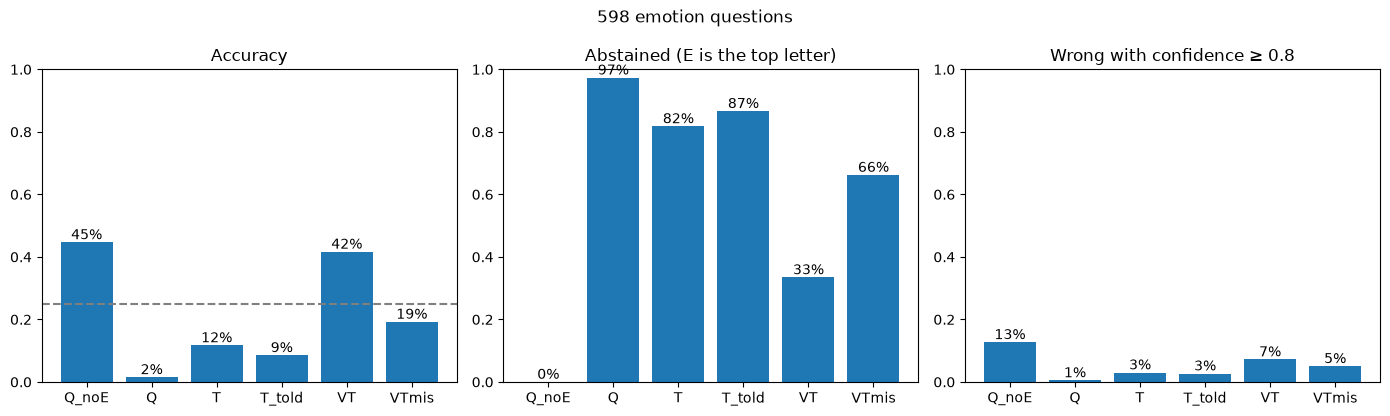

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "accuracy", "Accuracy"),
                       (axes[1], "abstain", "Abstained (E is the top letter)"),
                       (axes[2], "confidently_wrong", f"Wrong with confidence ≥ {HIGH_CONFIDENCE}")]:
    ax.bar(summary.index, summary[col], color="tab:blue")
    for i, value in enumerate(summary[col]):
        ax.text(i, value + 0.01, f"{value:.0%}", ha="center")
    ax.set(title=title, ylim=(0, 1))
axes[0].axhline(0.25, ls="--", c="gray")
fig.suptitle(f"{df.question_id.nunique()} emotion questions")
fig.tight_layout()
fig.savefig(FIGURES / "summary_by_condition.png", dpi=200)
plt.show()

### More plots

In [13]:
import numpy as np

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e2dc"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})

def bootstrap_ci(values, n_resamples=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [rng.choice(values, len(values)).mean() for _ in range(n_resamples)]
    return np.percentile(means, [2.5, 97.5])

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half

df["forced_answer"] = df[abcd].idxmax(axis=1).str[-1]
df["forced_correct"] = df.forced_answer == df.correct_answer_key
df["no_dialogue"] = df.question_id.map(all_questions.set_index("question_id").focused_n_words) == 0
df["outcome"] = np.where(df.abstain, "abstain", np.where(df.correct, "right", "wrong"))
with_e = [c for c in conditions if c != "Q_noE"]

#### 1. Abstention follows the evidence

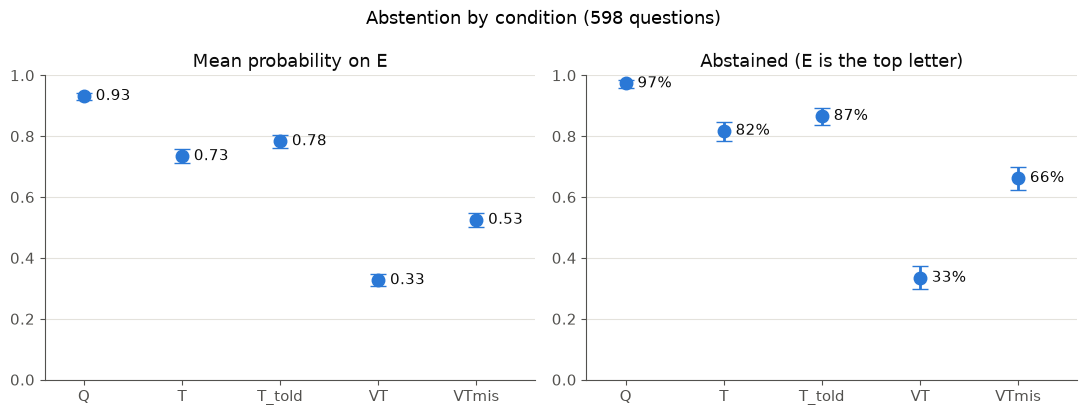

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title in zip(axes, ["Mean probability on E", "Abstained (E is the top letter)"]):
    for i, condition in enumerate(with_e):
        g = df[df.condition == condition]
        if title.startswith("Mean"):
            value, (lo, hi) = g.p_E.mean(), bootstrap_ci(g.p_E)
        else:
            value, (lo, hi) = g.abstain.mean(), wilson(g.abstain.sum(), len(g))
        ax.errorbar(i, value, yerr=[[value - lo], [hi - value]], fmt="o", ms=9, color=BLUE, capsize=6, lw=2)
        ax.text(i + 0.12, value, f"{value:.2f}" if title.startswith("Mean") else f"{value:.0%}", va="center", color=INK)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.4, len(with_e) - 0.4), title=title)
fig.suptitle(f"Abstention by condition ({df.question_id.nunique()} questions)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_condition.png", dpi=200)
plt.show()

#### 2. The video changes *whether* the model answers, not *what* it answers

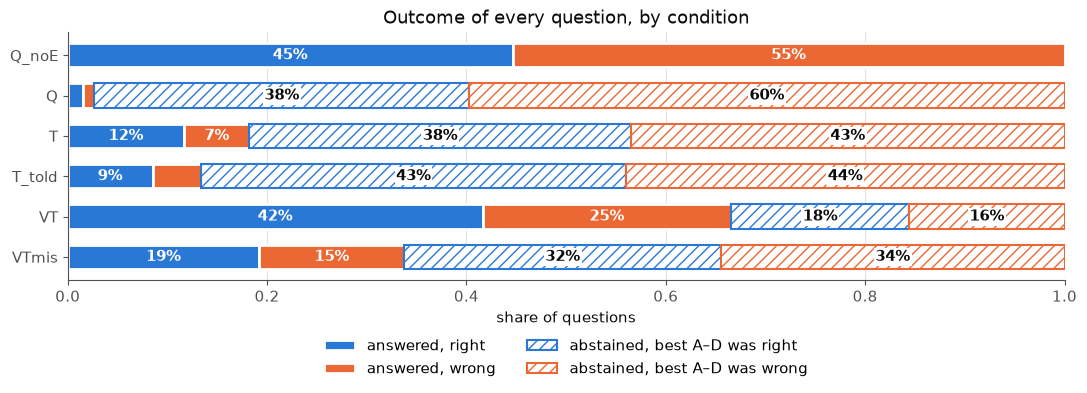

accuracy among answered: {'Q_noE': 0.446, 'Q': 0.562, 'T': 0.642, 'T_told': 0.638, 'VT': 0.626, 'VTmis': 0.569}
forced A-D accuracy:    {'Q_noE': 0.445, 'Q': 0.391, 'T': 0.5, 'T_told': 0.512, 'VT': 0.597, 'VTmis': 0.51}


In [15]:
parts = [("answered, right", ~df.abstain & df.correct, BLUE, None),
         ("answered, wrong", ~df.abstain & ~df.correct, ORANGE, None),
         ("abstained, best A–D was right", df.abstain & df.forced_correct, BLUE, "///"),
         ("abstained, best A–D was wrong", df.abstain & ~df.forced_correct, ORANGE, "///")]

fig, ax = plt.subplots(figsize=(11, 4.2))
rows = np.arange(len(conditions))
left = np.zeros(len(conditions))
for label, mask, color, hatch in parts:
    share = mask.groupby(df.condition).mean().reindex(conditions).values
    hatched = hatch is not None
    keep = share > 0
    ax.barh(rows[keep], share[keep], left=left[keep], color="white" if hatched else color, edgecolor=color if hatched else "white",
            hatch=hatch, linewidth=1.5 if hatched else 2, label=label, height=0.6)
    for y, (x, w) in enumerate(zip(left, share)):
        if w >= 0.06:
            ax.text(x + w / 2, y, f"{w:.0%}", ha="center", va="center", color=INK if hatched else "white",
                    fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1) if hatched else None)
    left += share
ax.set_yticks(rows, conditions)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="share of questions", title="Outcome of every question, by condition")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(FIGURES / "outcomes_by_condition.png", dpi=200)
plt.show()

print("accuracy among answered:", df[~df.abstain].groupby("condition").correct.mean().reindex(conditions).round(3).to_dict())
print("forced A-D accuracy:   ", df.groupby("condition").forced_correct.mean().reindex(conditions).round(3).to_dict())

#### 3. Question by question: P(E) with and without the (right) video

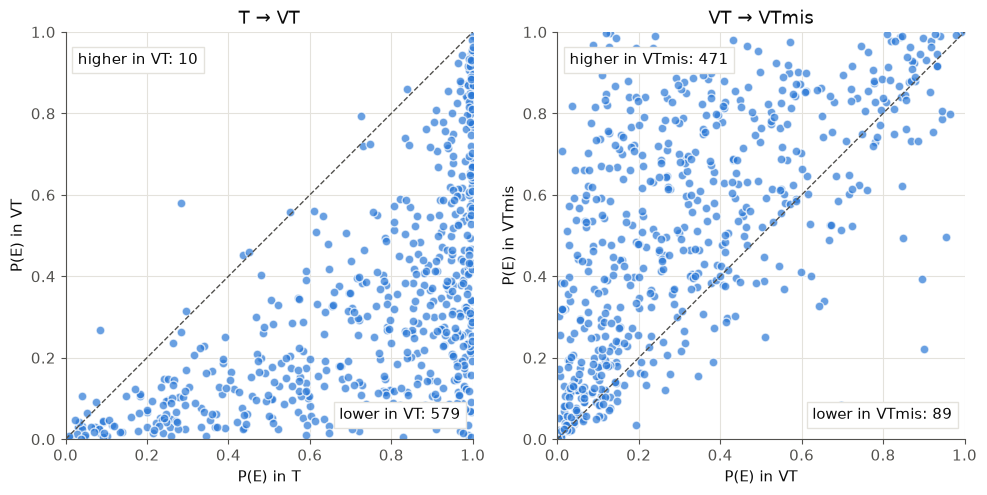

In [16]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (a, b) in zip(axes, [("T", "VT"), ("VT", "VTmis")]):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    ax.scatter(pE[a], pE[b], s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=1)
    up, down = (pE[b] > pE[a] + 0.01).sum(), (pE[b] < pE[a] - 0.01).sum()
    ax.text(0.03, 0.95, f"higher in {b}: {up}", transform=ax.transAxes, va="top", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.text(0.97, 0.05, f"lower in {b}: {down}", transform=ax.transAxes, ha="right", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"P(E) in {a}", ylabel=f"P(E) in {b}", title=f"{a} → {b}")
    ax.grid(axis="both", color=GRID)
fig.tight_layout()
fig.savefig(FIGURES / "p_E_per_question.png", dpi=200)
plt.show()

#### 4. Where the answers move

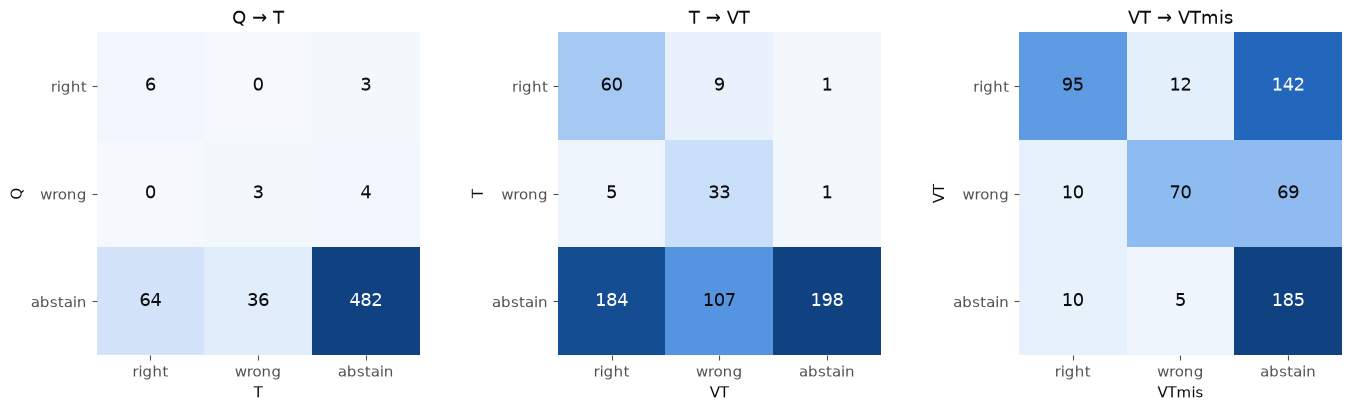

In [17]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#9ec5f4", "#2a78d6", "#104281"])
outcome = df.pivot(index="question_id", columns="condition", values="outcome")
labels = ["right", "wrong", "abstain"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (a, b) in zip(axes, [("Q", "T"), ("T", "VT"), ("VT", "VTmis")]):
    table = pd.crosstab(outcome[a], outcome[b]).reindex(index=labels, columns=labels, fill_value=0)
    ax.imshow(table.values, cmap=blues, vmin=0, vmax=table.values.max())
    for i in range(3):
        for j in range(3):
            n = table.values[i, j]
            ax.text(j, i, n, ha="center", va="center", fontsize=13,
                    color="white" if n > table.values.max() * 0.55 else INK)
    ax.set(xticks=range(3), xticklabels=labels, yticks=range(3), yticklabels=labels,
           xlabel=b, ylabel=a, title=f"{a} → {b}")
    ax.grid(False)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "outcome_transitions.png", dpi=200)
plt.show()

#### 5. Subgroups: visual-cue tag and clips without dialogue

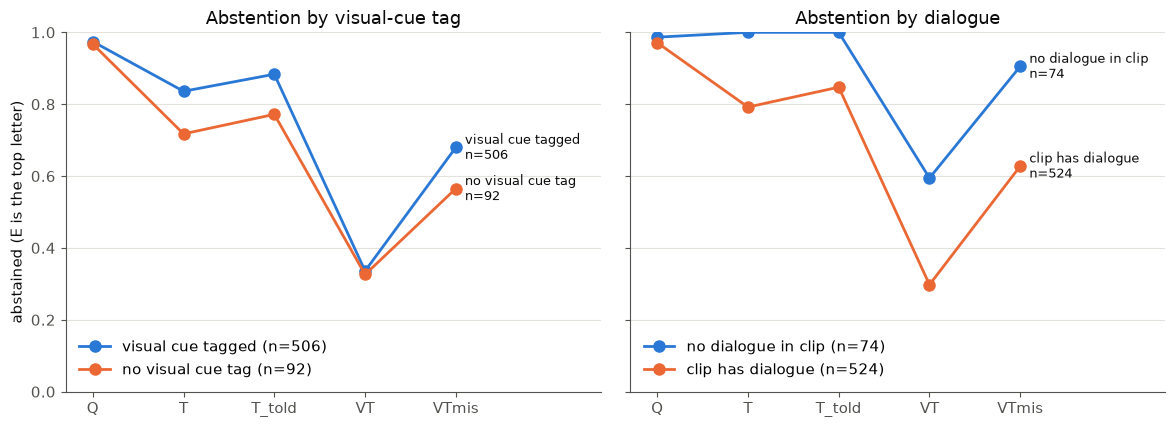

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (column, names) in zip(axes, [("cue_visual_any", {True: "visual cue tagged", False: "no visual cue tag"}),
                                      ("no_dialogue", {False: "clip has dialogue", True: "no dialogue in clip"})]):
    for value, color in [(True, BLUE), (False, ORANGE)]:
        g = df[(df[column] == value) & df.condition.isin(with_e)]
        rate = g.groupby("condition").abstain.mean().reindex(with_e)
        n = g.question_id.nunique()
        ax.plot(range(len(with_e)), rate.values, "o-", color=color, lw=2, ms=8, label=f"{names[value]} (n={n})")
        ax.text(len(with_e) - 1 + 0.1, rate.values[-1], f"{names[value]}\nn={n}", va="center", color=INK, fontsize=9)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.3, len(with_e) + 0.6),
           title=f"Abstention by {'visual-cue tag' if column == 'cue_visual_any' else 'dialogue'}")
    ax.legend(loc="lower left")
axes[0].set_ylabel("abstained (E is the top letter)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_subgroups.png", dpi=200)
plt.show()

## Explanations

In [19]:
explanations = df[["order", "question_id", "movie_title", "question", "condition", "option_order", "answer_shown", "answer",
                   "confidence", "p_E", "explanation", "evidence_answer", "explanation_hit_limit"]].sort_values(["order", "condition"])
explanations.to_csv(EXP_DIR / "explanations.csv", index=False)
print("explanations that hit the token limit:", explanations.explanation_hit_limit.sum())
pd.set_option("display.max_colwidth", None)
explanations.head(15)

explanations that hit the token limit: 0


,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit
1,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q,CBEDA,C,E,0.576965,0.996665,"The answer is C because the question does not provide any specific details or expressions of emotion from the man regarding knocking on the door, making it impossible to determine his feelings from the given information.",nothing,False
0,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q_noE,CBDA,C,D,0.920541,0.000000,"The answer is C because the context implies that the man feels nervous about knocking on the door, suggesting a sense of apprehension or uncertainty.",nothing,False
2,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T,CBEDA,C,E,0.429686,0.999116,"The answer is C because the transcript provided no dialogue, so there is no information to determine how the man feels about knocking on the door.",nothing,False
3,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T_told,CBEDA,C,E,0.479723,0.998325,The answer cannot be determined from the given transcript as it contains no dialogue or context about the man's feelings regarding knocking on the door.,nothing,False
4,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VT,CBEDA,C,E,0.883499,0.777496,"The video does not provide any explicit dialogue or facial expressions that indicate the man's feelings about knocking on the door, so it is not possible to determine his emotions from the given information.",video,False
5,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VTmis,CBEDA,C,E,0.462574,0.878580,"The video does not provide any dialogue or visual cues indicating the man's feelings about knocking on the door, so it is impossible to determine his emotions from the given information.",nothing,False
7,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q,CDAEB,D,E,0.837757,0.828207,The answer cannot be determined from the given information as there is no context provided about the young woman's feelings or reactions towards the older woman's violent reaction.,nothing,False
6,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q_noE,CDAB,C,A,0.952745,0.000000,"The answer is C because the context implies that the younger woman is likely to step back as a defensive response to the older woman's violent reaction, indicating fear or an attempt to avoid harm.",nothing,False
8,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T,CDAEB,C,A,0.888909,0.270367,"The answer is C because the dialogue shows the younger woman repeatedly saying ""Get off"" and ""Get your black hands off,"" indicating fear and a desire to avoid further harm, which aligns with feeling scared and stepping back.",transcript,False
9,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T_told,CDAEB,C,A,0.915966,0.386327,"The answer is C because the dialogue indicates that the younger woman is being physically pushed away and is reacting by stepping back, suggesting fear and an attempt to avoid further harm.",transcript,False


### Visual words in the explanations (keyword screen)

In [20]:
VISUAL_WORDS = ["face", "facial", "expression", "smile", "smiling", "frown", "eyes", "gaze", "tears", "crying",
                "body language", "posture", "gesture", "video", "visible"]
pattern = r"\b(?:" + "|".join(VISUAL_WORDS) + r")\b"
explanations["mentions_visual"] = explanations.explanation.str.contains(pattern, case=False)
display(explanations.groupby("condition").mentions_visual.mean().reindex(conditions).round(3))
explanations[(explanations.condition == "VTmis") & explanations.mentions_visual & (explanations.answer != "E")].head(10)

condition
Q_noE     0.107
Q         0.077
T         0.070
T_told    0.062
VT        0.523
VTmis     0.622
Name: mentions_visual, dtype: float64

,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit,mentions_visual
11,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,VTmis,CDAEB,C,A,0.834672,0.090651,"The young woman's body language, such as stepping back and crossing her arms, indicates that she feels scared and is trying to avoid further confrontation.",both,False,True
35,5,vXeRH,"MOTHER, CHILD",Why did the man return despite being so determined to leave?,VTmis,CEDBA,E,A,0.965935,0.022212,"The answer is based on the context provided in the video, where the man's actions and dialogue suggest a deep emotional connection and a realization that his mother's well-being is crucial to him, despite his previous anger and determination to leave.",both,False,True
137,22,UoFUT,SOMETHING LIKE LONELINESS,What is the woman's emotional progression during the conversation?,VTmis,DECBA,E,A,0.557602,0.043768,"The woman's emotional progression is inferred from her body language and facial expressions, such as her initial annoyance, followed by disgust, and then nervousness as she reacts to the man's comments about her sounds and his proposition.",both,False,True
215,35,tWgjm,GET READY WITH ME,Why is the man in olive green seated in front of the desktop moving his cursor between video thumbnails without clicking any of them?\n,VTmis,EACBD,B,A,0.862888,0.104568,"The answer is based on the context provided in the video where the man appears to be struggling emotionally after an eventful day, reflecting on his feelings and the impact on his professional life, and the visual cue of him scrolling through video thumbnails without selecting any, suggesting indecision and emotional turmoil.",both,False,True
251,41,7n_W8,THE ARK,What is the woman feeling in this situation?,VTmis,EDBAC,C,B,0.472499,0.294273,"The woman's expression and body language, along with the context of the dialogue, suggest that she is feeling scared due to the implication of being exploited or manipulated by someone.",both,False,True
257,42,d6r05,SAN MIGUEL,Why did the girl break the statue of the saint?,VTmis,EBDCA,D,C,0.782693,0.133540,"The answer is based on the context provided in the video where the girl expresses frustration about her mother's illness and the belief that the statue is causing it, leading her to break it.",both,False,True
293,48,_aNhQ,ITALIAN MIRACLE,What is the woman feeling when she smiles?,VTmis,BCAED,C,A,0.898153,0.166948,"The woman's smile in the context of discussing a serious topic like divorce suggests a sense of relief or acceptance, as indicated by her response ""Grazie"" (Thank you) and the mention of ""riassolvo"" (I absolve), which implies a resolution or forgiveness.",both,False,True
383,63,E0aVA,MY BROTHER IS A MERMAID,Why is the woman in white hanging up the glittery pants on the clothesline she had previously thrown into the bin?,VTmis,CABED,C,B,0.710548,0.228514,"The answer is based on the context provided in the video, where the woman in white is shown handling the pants with care, indicating a shift towards acceptance of her son's identity, despite her earlier concerns.",both,False,True
479,79,dBuuK,EVERY OTHER WEEK,Why does he apologize even though the woman did not say anything?,VTmis,ACDEB,E,B,0.660000,0.176460,"The answer is based on the context provided in the video where the man says ""I'm sorry"" after a lull in the conversation, suggesting he perceived an offense or discomfort from the woman's reaction.",both,False,True
629,104,jI7Xf,REBEL,How does the little boy feel about the teddy bear?,VTmis,ABCDE,D,D,0.947658,0.141394,"The answer is based on the context provided in the video where the boy expresses embarrassment about wanting the teddy bear, indicating his awareness of its significance to the girl who was crying.",both,False,True


#### 6. What the explanations talk about (keyword screens)

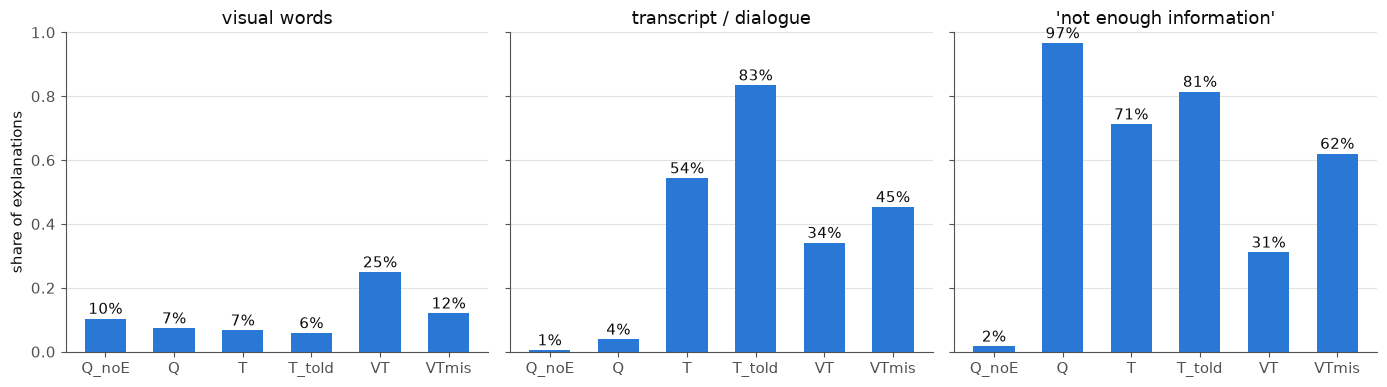

In [21]:
screens = {
    "visual words": r"\b(?:face|facial|expression|smil\w*|frown\w*|eyes|gaze|tears|cry\w*|body language|posture|gesture\w*)\b",
    "transcript / dialogue": r"\b(?:transcript|dialogue|says|said)\b",
    "'not enough information'": r"does not provide|not enough|cannot be determined|impossible to determine|no (?:information|dialogue|context)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (title, pattern) in zip(axes, screens.items()):
    share = explanations.explanation.str.contains(pattern, case=False).groupby(explanations.condition).mean().reindex(conditions)
    ax.bar(conditions, share.values, color=BLUE, width=0.6)
    for i, v in enumerate(share.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", color=INK)
    ax.set(title=title, ylim=(0, 1))
axes[0].set_ylabel("share of explanations")
fig.tight_layout()
fig.savefig(FIGURES / "explanation_screens.png", dpi=200)
plt.show()

## Told that a video exists (T_told vs T)

Abstention in T and T_told, split by whether the video changed the answer (VT vs T).

In [22]:
if {"T", "T_told", "VT"} <= set(conditions):
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = (answers["VT"] != answers["T"]).rename("video_mattered")
    told = df[df.condition.isin(["T", "T_told"])].merge(video_mattered, left_on="question_id", right_index=True)
    display(told.pivot_table(index="video_mattered", columns="condition", values=["abstain", "p_E"], aggfunc="mean").round(3))
    print("questions per group:", video_mattered.value_counts().to_dict())

abstain           p_E       
condition            T T_told      T T_told
video_mattered                             
False            0.685  0.768  0.705  0.747
True             0.942  0.958  0.761  0.817

questions per group: {True: 309, False: 289}


## Evidence question (branch B)

In [23]:
evidence_names = list(EVIDENCE)
display(pd.crosstab(df.condition, df.evidence_answer, normalize="index")
        .reindex(index=conditions, columns=evidence_names, fill_value=0).round(3))
display(pd.crosstab([df.condition, df.abstain], df.evidence_answer, normalize="index")
        .reindex(columns=evidence_names, fill_value=0).round(3))
claims_video = df.evidence_answer.isin(["video", "both"])
print("claimed a video:", claims_video.groupby(df.condition).mean().reindex(conditions).round(3).to_dict())
print("mean evidence_mass_on_letters:", round(df.evidence_mass_on_letters.mean(), 3))

evidence_answer,nothing,transcript,video,both
condition,,,,
Q_noE,0.861,0.092,0.028,0.018
Q,0.997,0.003,0.000,0.000
T,0.202,0.796,0.002,0.000
T_told,0.291,0.709,0.000,0.000
VT,0.033,0.027,0.129,0.811
VTmis,0.284,0.090,0.070,0.555


evidence_answer    nothing  transcript  video   both
condition abstain                                   
Q         False      0.938       0.062  0.000  0.000
          True       0.998       0.002  0.000  0.000
Q_noE     False      0.861       0.092  0.028  0.018
T         False      0.000       1.000  0.000  0.000
          True       0.247       0.751  0.002  0.000
T_told    False      0.000       1.000  0.000  0.000
          True       0.336       0.664  0.000  0.000
VT        False      0.000       0.035  0.090  0.874
          True       0.100       0.010  0.205  0.685
VTmis     False      0.005       0.099  0.045  0.851
          True       0.427       0.086  0.083  0.404

claimed a video: {'Q_noE': 0.047, 'Q': 0.0, 'T': 0.002, 'T_told': 0.0, 'VT': 0.94, 'VTmis': 0.625}
mean evidence_mass_on_letters: 0.995


## Option position

In [24]:
e_conditions = [c for c in conditions if c != "Q_noE"]
df["e_shown_as"] = df.option_order.str.find("E").map(dict(enumerate(SHOWN)))
display(df[df.condition.isin(e_conditions)]
        .pivot_table(index="condition", columns="e_shown_as", values="abstain", aggfunc="mean")
        .reindex(e_conditions).round(3))
display(pd.crosstab(df.condition, df.answer_shown, normalize="index").reindex(conditions).round(3))

e_shown_as,A,B,C,D,E
condition,,,,,
Q,0.902,0.991,0.983,0.986,0.992
T,0.716,0.764,0.866,0.833,0.880
T_told,0.755,0.830,0.882,0.913,0.917
VT,0.147,0.330,0.412,0.377,0.368
VTmis,0.471,0.623,0.739,0.732,0.699


answer_shown,A,B,C,D,E
condition,,,,,
Q_noE,0.212,0.256,0.249,0.283,0.000
Q,0.156,0.179,0.199,0.234,0.232
T,0.140,0.167,0.211,0.239,0.242
T_told,0.142,0.167,0.197,0.253,0.241
VT,0.135,0.182,0.236,0.221,0.226
VTmis,0.125,0.176,0.214,0.247,0.237


## Run time

In [25]:
seconds = df.score_seconds + df.explain_seconds + df.evidence_seconds
display(seconds.groupby(df.condition).mean().reindex(conditions).round(1).rename("seconds per question"))
print(f"{seconds.sum() / 3600:.1f} GPU-hours for {df.question_id.nunique()} questions (model loading not included)")

condition
Q_noE      1.5
Q          1.2
T          1.2
T_told     1.2
VT        16.8
VTmis     16.7
Name: seconds per question, dtype: float64

6.4 GPU-hours for 598 questions (model loading not included)


## Additional tests (added 2026-10-19)

In [26]:
from scipy.stats import binomtest, chi2_contingency, chisquare, mannwhitneyu

abstained = df.pivot(index="question_id", columns="condition", values="abstain")
for condition in e_conditions:
    lo, hi = wilson(abstained[condition].sum(), len(abstained))
    print(f"{condition:7} abstained {abstained[condition].mean():.1%}  95% CI [{lo:.1%}, {hi:.1%}]")
print()
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    start = int((~abstained[a] & abstained[b]).sum())
    stop = int((abstained[a] & ~abstained[b]).sum())
    print(f"{a} -> {b}: {start} start abstaining, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")

Q       abstained 97.3%  95% CI [95.7%, 98.3%]
T       abstained 81.8%  95% CI [78.5%, 84.7%]
T_told  abstained 86.6%  95% CI [83.7%, 89.1%]
VT      abstained 33.4%  95% CI [29.8%, 37.3%]
VTmis   abstained 66.2%  95% CI [62.3%, 69.9%]

Q -> T: 7 start abstaining, 100 stop; exact McNemar p = 3.5e-22
T -> T_told: 31 start abstaining, 2 stop; exact McNemar p = 1.3e-07
T -> VT: 2 start abstaining, 291 stop; exact McNemar p = 5.4e-84
VT -> VTmis: 211 start abstaining, 15 stop; exact McNemar p = 1.9e-45
T -> VTmis: 17 start abstaining, 110 stop; exact McNemar p = 7.4e-18


In [27]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
answers = df.pivot(index="question_id", columns="condition", values="answer")
video_mattered = answers["VT"] != answers["T"]
rise = pE["T_told"] - pE["T"]
print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
      f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
      f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

P(E) rise T -> T_told: video mattered +0.056 (n = 309), did not +0.042 (n = 289); Mann-Whitney p = 0.0021


In [28]:
for condition in e_conditions:
    g = df[df.condition == condition]
    p = chi2_contingency(pd.crosstab(g.e_shown_as, g.abstain))[1]
    print(f"abstention vs letter of 'Cannot tell', {condition}: chi-square p = {p:.2g}")
letters = df[df.condition == "Q_noE"].answer_shown.value_counts().reindex(["A", "B", "C", "D"])
print(f"Q_noE answers by shown letter: {letters.to_dict()}; chi-square vs equal p = {chisquare(letters).pvalue:.2g}")

abstention vs letter of 'Cannot tell', Q: chi-square p = 7.1e-05
abstention vs letter of 'Cannot tell', T: chi-square p = 0.0055
abstention vs letter of 'Cannot tell', T_told: chi-square p = 0.0013
abstention vs letter of 'Cannot tell', VT: chi-square p = 0.0003
abstention vs letter of 'Cannot tell', VTmis: chi-square p = 6.4e-05
Q_noE answers by shown letter: {'A': 127, 'B': 153, 'C': 149, 'D': 169}; chi-square vs equal p = 0.11


In [29]:
told = df[df.condition == "T_told"]
mentions_video = told.explanation.str.contains(r"\bvideo", case=False)
print(f"T_told explanations mentioning the video: {mentions_video.mean():.1%} "
      f"(abstentions {mentions_video[told.abstain].mean():.1%}, answers {mentions_video[~told.abstain].mean():.1%})")

T_told explanations mentioning the video: 0.7% (abstentions 0.8%, answers 0.0%)
